### KMeans Clustering

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X, _ = make_blobs(n_samples=500, centers=4,
                  cluster_std=0.9, random_state=42)
X = StandardScaler().fit_transform(X)

model = KMeans(
    n_clusters=4,
    init="k-means++",    # 智慧初始化
    n_init=10,            # 跑 10 次取最佳
    max_iter=300,
    random_state=42,
)
labels = model.fit_predict(X)
centers = model.cluster_centers_
print(f"inertia = {model.inertia_:.2f}")

inertia = 23.47


### KMeans Clustering Visualization

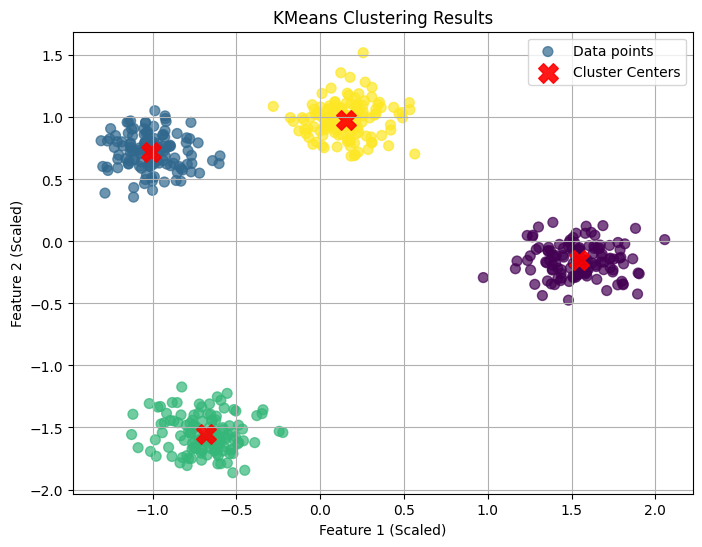

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.7, label='Data points')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.9, marker='X', label='Cluster Centers')
plt.title('KMeans Clustering Results')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
inertias = []
for k in range(1, 11):
    model = KMeans(n_clusters=k,
                   init="k-means++",
                   n_init=10,
                   max_iter=300,
                   random_state=42)
    model.fit(X)
    inertias.append(model.inertia_)

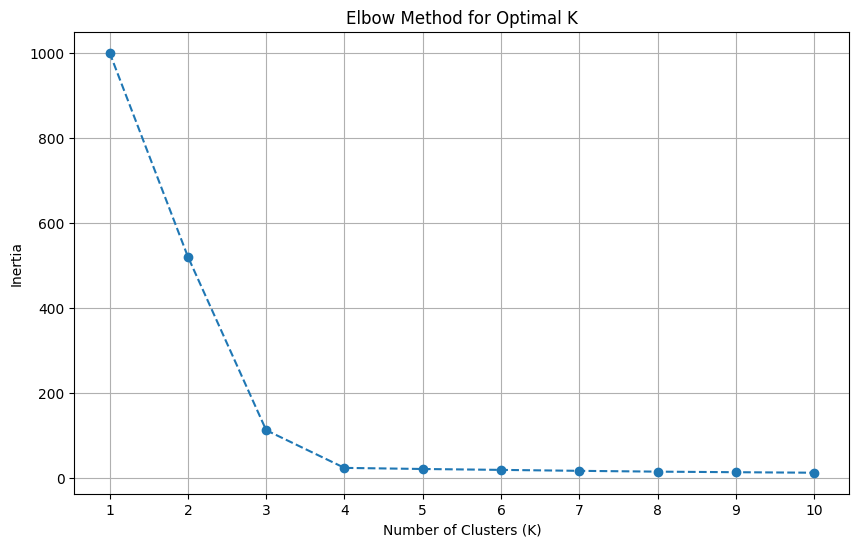

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertias, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

階層式分群演算法

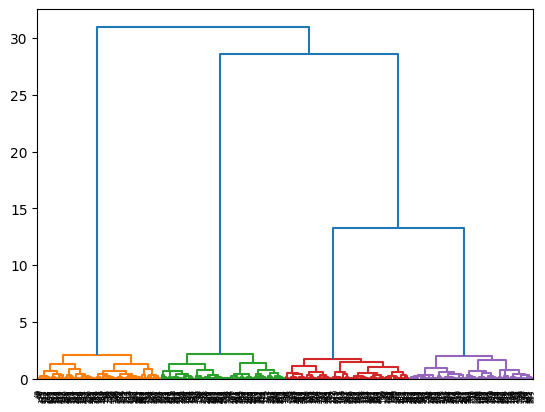

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# 1. 直接做分群（指定 k 或距離門檻）
model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward",         # single / complete / average / ward
    metric="euclidean",
)
labels = model.fit_predict(X)

# 2. 畫 dendrogram 看樹狀結構
Z = linkage(X, method="ward")
dendrogram(Z, color_threshold=4)
plt.show()

# 3. 不指定 k，改用距離門檻自動切
model2 = AgglomerativeClustering(
    n_clusters=None, distance_threshold=5.0)


### Agglomerative Clustering Visualization

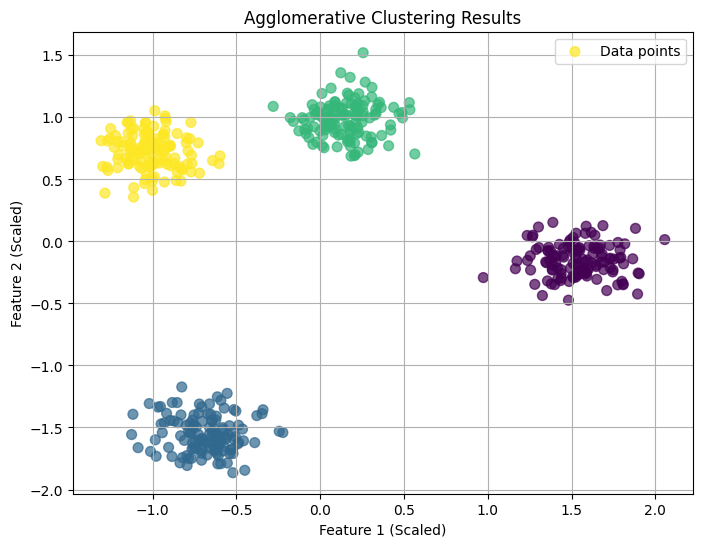

In [ ]:
import matplotlib.pyplot as plt

# Re-run AgglomerativeClustering to get labels for plotting
model_agg = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward",
    metric="euclidean",
)
labels_agg = model_agg.fit_predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_agg, cmap='viridis', s=50, alpha=0.7, label='Data points')
plt.title('Agglomerative Clustering Results')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

DBSCAN

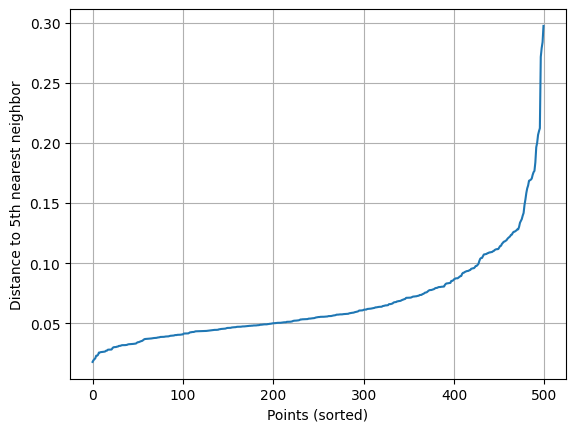

In [ ]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

# 1. 用 k-distance plot 找 eps
nbrs = NearestNeighbors(n_neighbors=5).fit(X)
dist, _ = nbrs.kneighbors(X)
k_dist = np.sort(dist[:, -1])     # 找拐點當 eps


plt.plot(k_dist)
plt.xlabel("Points (sorted)")
plt.ylabel("Distance to 5th nearest neighbor")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
# 2. 訓練 DBSCAN
model = DBSCAN(
    eps=0.25,           # 鄰居半徑
    min_samples=5,       # 核心點門檻
    metric="euclidean",
)
labels = model.fit_predict(X)

# 3. 雜訊點 = -1
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise    = list(labels).count(-1)
print(f"clusters={n_clusters}, noise={n_noise}")

clusters=4, noise=0


### DBSCAN Clustering Visualization

/tmp/ipykernel_471/2501396052.py:17: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(xy[:, 0], xy[:, 1], s=50, c=col, marker='o', alpha=0.7, label=f'Cluster {k}' if k != -1 else 'Noise')


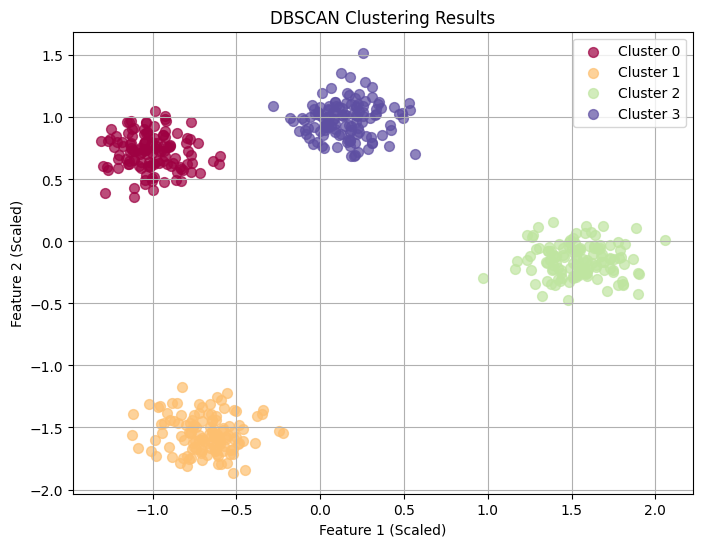

In [ ]:
import matplotlib.pyplot as plt

# Create a scatter plot of the data points, colored by their cluster labels
plt.figure(figsize=(8, 6))

unique_labels = set(labels)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = 'k'

    class_member_mask = (labels == k)

    xy = X[class_member_mask]
    plt.scatter(xy[:, 0], xy[:, 1], s=50, c=col, marker='o', alpha=0.7, label=f'Cluster {k}' if k != -1 else 'Noise')

plt.title('DBSCAN Clustering Results')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

OPTICS

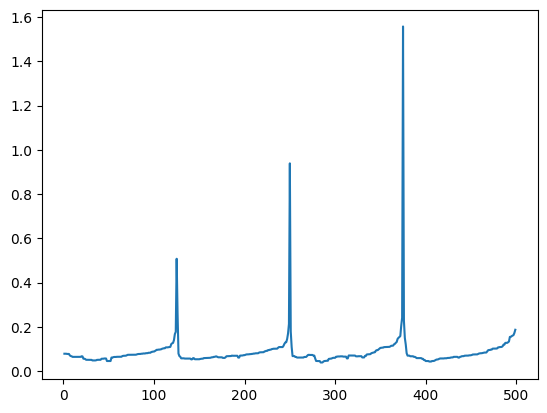

In [ ]:
from sklearn.cluster import OPTICS, cluster_optics_dbscan
import matplotlib.pyplot as plt

# 用 xi 法自動找群（適合密度不均）
model = OPTICS(
    min_samples=10,
    xi=0.05,                # 谷邊界的最小相對斜率
    min_cluster_size=0.05,   # 小於 5% 視為不成群
    metric="minkowski",
)
model.fit(X)
labels = model.labels_

# 也能像 DBSCAN 那樣用 eps 切
labels_db = cluster_optics_dbscan(
    reachability=model.reachability_,
    core_distances=model.core_distances_,
    ordering=model.ordering_, eps=0.3)

# Reachability plot 觀察密度結構
plt.plot(model.reachability_[model.ordering_])

MeanShift

In [ ]:

from sklearn.cluster import MeanShift, estimate_bandwidth

# 1. 自動估 bandwidth（基於 k-NN 距離）
bw = estimate_bandwidth(
    X, quantile=0.2,    # 取 20% 分位的 NN 距離
    n_samples=500)

# 2. 建立模型
model = MeanShift(
    bandwidth=bw,
    bin_seeding=True,   # 加速：用網格初始化種子點
    cluster_all=True,
)
labels = model.fit_predict(X)
centers = model.cluster_centers_

print(f"自動找到 {len(centers)} 個群")


自動找到 4 個群


### MeanShift Clustering Visualization

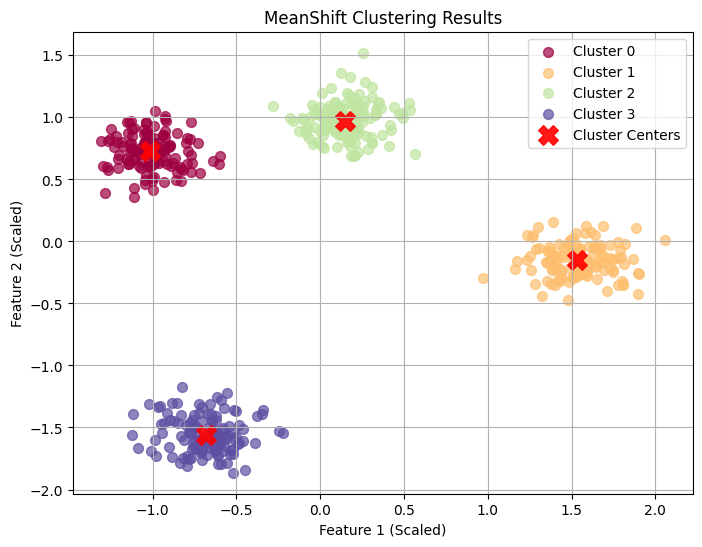

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Get unique labels (clusters) and assign a color to each
unique_labels = np.unique(labels)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

# Plot each cluster
for k, col in zip(unique_labels, colors):
    if k == -1: # Noise points if any
        col = 'k' # Black color for noise
    my_members = labels == k
    plt.scatter(X[my_members, 0], X[my_members, 1], color=col, s=50, alpha=0.7, label=f'Cluster {k}')

# Plot cluster centers
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.9, marker='X', label='Cluster Centers')

plt.title('MeanShift Clustering Results')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

###GMM

In [ ]:
from sklearn.mixture import GaussianMixture
import numpy as np

# 1. 用 BIC 選最佳 k 與 covariance 形狀
best, best_bic = None, np.inf
for k in range(1, 10):
    for cov in ["full", "tied", "diag", "spherical"]:
        gmm = GaussianMixture(n_components=k,
                covariance_type=cov, random_state=42).fit(X)
        if gmm.bic(X) < best_bic:
            best, best_bic = gmm, gmm.bic(X)

# 2. 硬分群（最大後驗）vs 軟分群（機率）
labels = best.predict(X)            # shape (n,)
probs  = best.predict_proba(X)      # shape (n, k)

# 3. 生成新樣本
new_X, new_y = best.sample(100)

### GMM Clustering Visualization

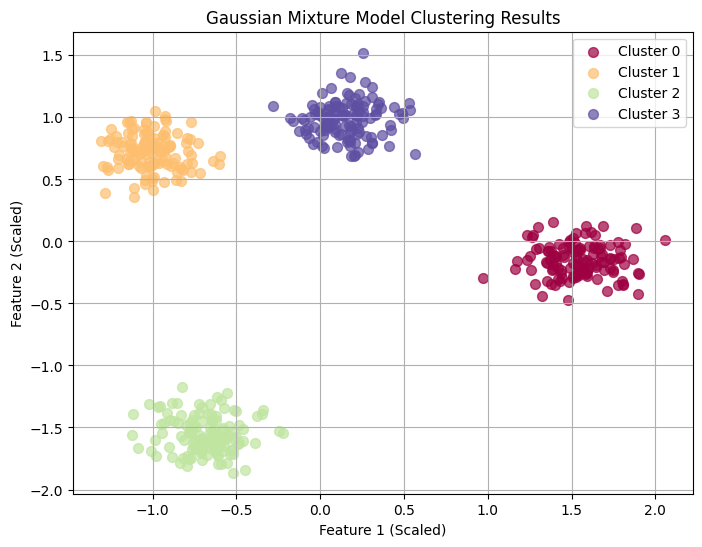

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Get unique labels (clusters) and assign a color to each
unique_labels = np.unique(labels)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

# Plot each cluster
for k, col in zip(unique_labels, colors):
    my_members = labels == k
    plt.scatter(X[my_members, 0], X[my_members, 1], color=col, s=50, alpha=0.7, label=f'Cluster {k}')

plt.title('Gaussian Mixture Model Clustering Results')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

### Gaussian Distribution Visualization with GMM Ellipses

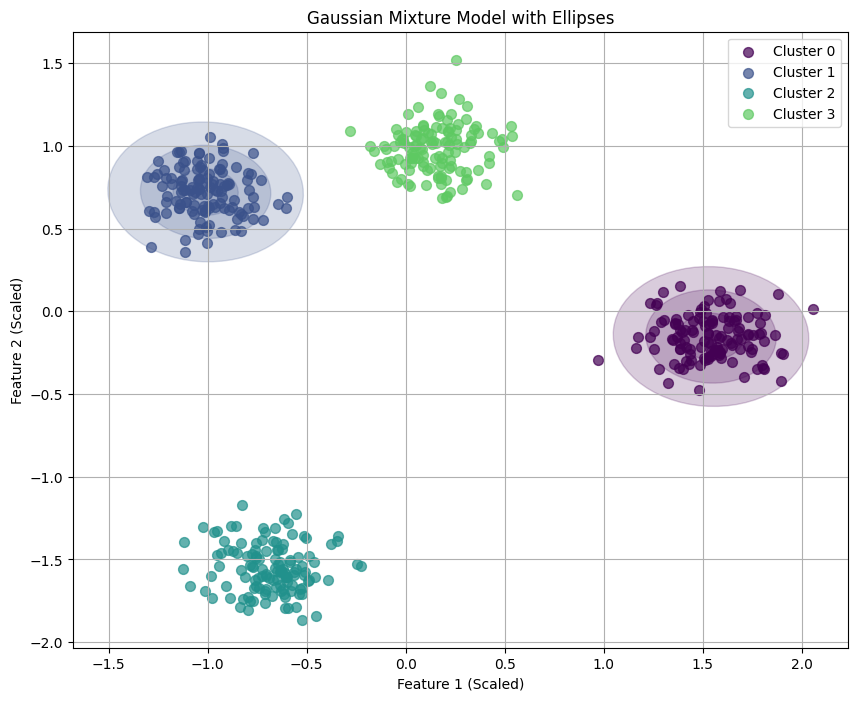

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draw an ellipse with a given position and covariance"""
    ax = ax or plt.gca()

    # Convert covariance to principal axes
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        # Asume spherical covariance
        angle = 0
        width, height = 2 * np.sqrt(covariance)

    # Draw the Ellipse
    for nstd in range(1, 4):
        ax.add_patch(Ellipse(xy=tuple(position), width=nstd * width, height=nstd * height,
                             angle=angle, **kwargs))

plt.figure(figsize=(10, 8))

# Get unique labels to iterate through clusters and plot them individually for legend
unique_labels = np.unique(labels)

for i, label_val in enumerate(unique_labels):
    color = plt.cm.viridis(i / len(unique_labels))
    cluster_mask = (labels == label_val)
    plt.scatter(X[cluster_mask, 0], X[cluster_mask, 1], s=50, color=color, alpha=0.7,
                label=f'Cluster {label_val}', zorder=1)

# Plot the Gaussian ellipses for each cluster
for i, (mean, cov, weight) in enumerate(zip(best.means_, best.covariances_, best.weights_)):
    color = plt.cm.viridis(i / len(unique_labels))

    # Special handling for covariance_type if not 'full'
    if best.covariance_type == 'tied':
        # cov is the shared covariance matrix for all clusters
        cov_matrix = best.covariances_
    elif best.covariance_type == 'diag':
        # cov is an array of diagonal elements
        cov_matrix = np.diag(cov)
    elif best.covariance_type == 'spherical':
        # cov is a scalar representing spherical covariance
        cov_matrix = np.diag(cov * np.ones(X.shape[1]))
    else: # 'full'
        # cov is a full covariance matrix
        cov_matrix = cov

    draw_ellipse(mean, cov_matrix, alpha=0.2, color=color)

plt.title('Gaussian Mixture Model with Ellipses')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.grid(True)
plt.legend()
plt.show()

###Spectral Clustering

In [ ]:
from sklearn.cluster import SpectralClustering
from sklearn.datasets import make_circles

X, _ = make_circles(n_samples=500,
                   factor=0.5, noise=0.05)

# 用 k-NN 圖建立相似度（推薦於流形資料）
model = SpectralClustering(
    n_clusters=2,
    affinity="nearest_neighbors",   # or "rbf"
    n_neighbors=10,
    assign_labels="kmeans",         # 最後用 K-Means
    random_state=42,
)
labels = model.fit_predict(X)

# RBF kernel 版本（小資料、密度均勻）
m2 = SpectralClustering(n_clusters=2,
       affinity="rbf", gamma=1.0)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


### Spectral Clustering (RBF Kernel) Visualization

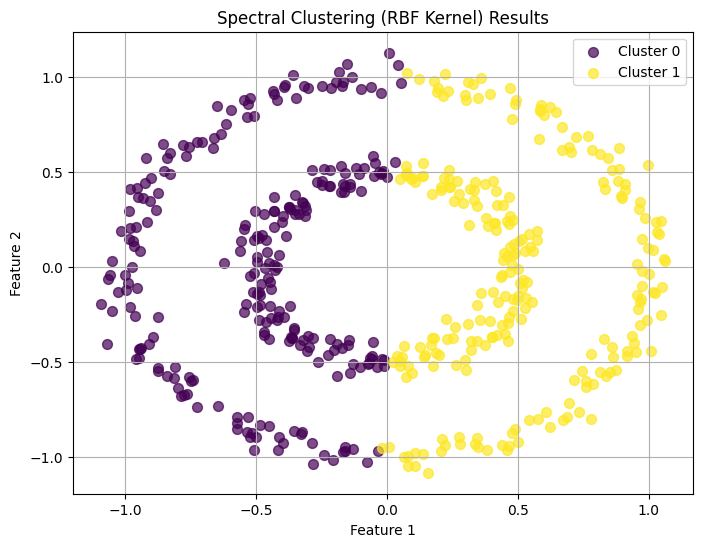

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Fit and predict with m2 to get labels
labels_m2 = m2.fit_predict(X)

plt.figure(figsize=(8, 6))

# Get unique labels and assign a color to each
unique_labels_m2 = np.unique(labels_m2)
colors_m2 = plt.cm.viridis(np.linspace(0, 1, len(unique_labels_m2)))

# Plot each cluster
for k, col in zip(unique_labels_m2, colors_m2):
    cluster_mask = (labels_m2 == k)
    plt.scatter(X[cluster_mask, 0], X[cluster_mask, 1], c=[col], s=50, alpha=0.7, label=f'Cluster {k}')

plt.title('Spectral Clustering (RBF Kernel) Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

###Birch

In [ ]:
import numpy as np

def chunks(arr, size):
    """Yield successive n-sized chunks from arr."""
    for i in range(0, len(arr), size):
        yield arr[i:i + size]

In [ ]:
from sklearn.cluster import Birch
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=100_000,    # 10 萬筆
                  centers=6, random_state=42)

model = Birch(
    threshold=0.3,     # CF 子群最大半徑（越小越細）
    branching_factor=50,# B-tree 子節點上限
    n_clusters=6,      # 最後階段要切的群數
)

# 1. 一次性 fit
labels = model.fit_predict(X)

# 2. 串流：分批 partial_fit（記憶體友善）
for batch in chunks(X, size=10_000):
    model.partial_fit(batch)
final_labels = model.predict(X)

### Birch Clustering Visualization

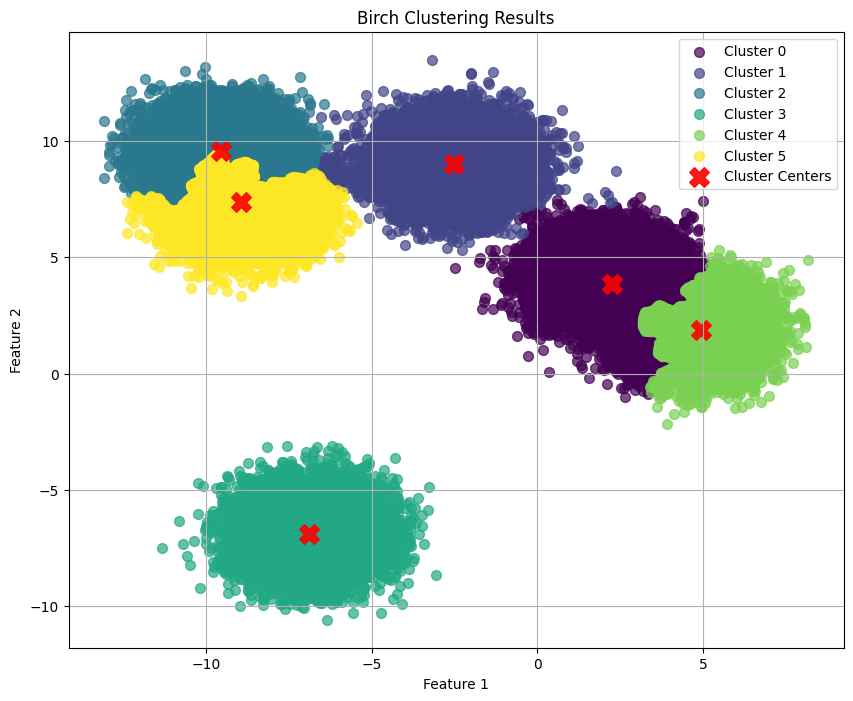

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

# Get unique labels and assign a color to each
unique_labels_birch = np.unique(final_labels)
colors_birch = plt.cm.viridis(np.linspace(0, 1, len(unique_labels_birch)))

# Plot each cluster
for k, col in zip(unique_labels_birch, colors_birch):
    if k == -1: # Handle noise if present (though Birch typically doesn't produce noise labels)
        col = 'k'
    cluster_mask = (final_labels == k)
    plt.scatter(X[cluster_mask, 0], X[cluster_mask, 1], c=[col], s=50, alpha=0.7, label=f'Cluster {k}')

# Calculate and plot cluster centers
birch_centers = np.array([X[final_labels == k].mean(axis=0) for k in unique_labels_birch if k != -1])
if len(birch_centers) > 0:
    plt.scatter(birch_centers[:, 0], birch_centers[:, 1], c='red', s=200, alpha=0.9, marker='X', label='Cluster Centers')

plt.title('Birch Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

## evaluate_clustering

For evaluation, we will re-generate a dataset `X` with known ground truth labels `y_true` to demonstrate both internal and external clustering metrics. We will use 4 centers for consistency with the KMeans example.

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Regenerate X and y_true for evaluation metrics
X_eval, y_true = make_blobs(n_samples=500, centers=4,
                  cluster_std=0.9, random_state=42)
X_eval = StandardScaler().fit_transform(X_eval)

In [ ]:
from sklearn import metrics
from sklearn.cluster import KMeans

# Use the regenerated X_eval for evaluation
labels_pred = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_eval)

# --- 內部指標（沒有 ground truth）------------------------------------
sil = metrics.silhouette_score(X_eval, labels_pred)              # [-1, 1]  ↑ 越大越好
ch  = metrics.calinski_harabasz_score(X_eval, labels_pred)       # [0, +∞)  ↑ 越大越好
db  = metrics.davies_bouldin_score(X_eval, labels_pred)          # [0, +∞)  ↓ 越小越好

# --- 外部指標（有 ground truth y_true 時）---------------------------
# Note: y_true is now available from the cell above
ari  = metrics.adjusted_rand_score(y_true, labels_pred)               # [-1, 1] ↑
nmi  = metrics.normalized_mutual_info_score(y_true, labels_pred)      # [0, 1]  ↑
vmes = metrics.v_measure_score(y_true, labels_pred)                   # [0, 1]  ↑

print(f"Silhouette={sil:.3f} | CH={ch:.1f} | DB={db:.3f} | ARI={ari:.3f} | NMI={nmi:.3f} | VMES={vmes:.3f}")

Silhouette=0.819 | CH=6878.9 | DB=0.253 | ARI=1.000 | NMI=1.000 | VMES=1.000


### 最小輪廓係數（Minimum Silhouette Score）

In [ ]:
from sklearn.metrics import silhouette_samples
import numpy as np

sil = silhouette_samples(X_eval, labels_pred)

print("平均 :", sil.mean())
print("中位數 :", np.median(sil))
print("最小 :", sil.min())
print("負分比例 :", np.mean(sil < 0))

平均 : 0.818694008438628
中位數 : 0.8285640683733597
最小 : 0.4301617678290447
負分比例 : 0.0


### 畫出負分分布

In [ ]:
from sklearn.metrics import silhouette_samples
import numpy as np

# 每一筆資料的 Silhouette Score
sil_samples = silhouette_samples(X_eval, labels_pred)

# 平均 Silhouette（等同 silhouette_score）
print(sil_samples.mean())

# 負分的點
negative = sil_samples < 0

print("負分點數：", negative.sum())
print("總點數：", len(sil_samples))
print("負分比例：", negative.mean())

0.818694008438628
負分點數： 0
總點數： 500
負分比例： 0.0


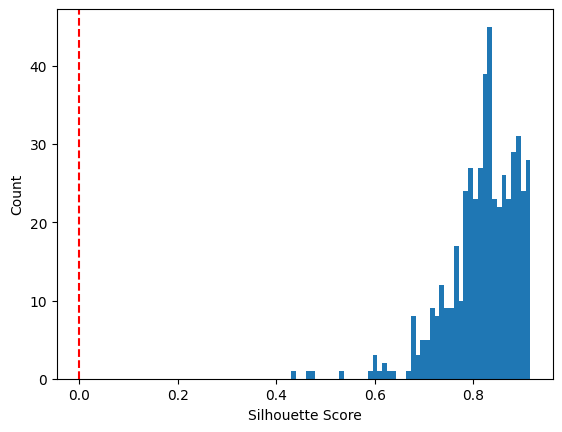

In [ ]:
import matplotlib.pyplot as plt

plt.hist(sil_samples, bins=50)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Silhouette Score")
plt.ylabel("Count")
plt.show()

### Evaluation Clustering Results Visualization

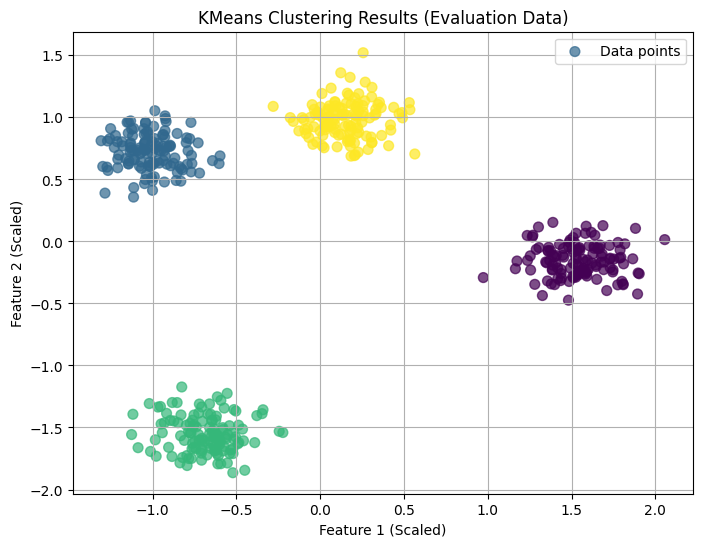

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Recompute labels_pred to ensure it's consistent with X_eval
labels_pred = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_eval)

plt.figure(figsize=(8, 6))
plt.scatter(X_eval[:, 0], X_eval[:, 1], c=labels_pred, cmap='viridis', s=50, alpha=0.7, label='Data points')
plt.title('KMeans Clustering Results (Evaluation Data)')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

###make_circles

In [ ]:
from sklearn.datasets import make_circles

X, _ = make_circles(n_samples=500,
                   factor=0.5, noise=0.05)

###Make

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
X, _ = make_blobs(n_samples=500, centers=4,
                  cluster_std=0.9, random_state=42)
X = StandardScaler().fit_transform(X)

###END-TO-END · pipeline_demo

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# 1. 標準化 + PCA 的前處理
prep = Pipeline([
    ("scale", StandardScaler()),
    ("pca",   PCA(n_components=0.95)),
])
X_p = prep.fit_transform(X)

# 2. 自動搜尋最佳 k（K-Means）
scores = {}
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=10,
                  random_state=42).fit_predict(X_p)
    scores[k] = silhouette_score(X_p, lab)
best_k = max(scores, key=scores.get)

# 3. 多模型 bake-off
models = {
    "KMeans": KMeans(n_clusters=best_k, n_init=10),
    "GMM":    GaussianMixture(n_components=best_k),
    "DBSCAN": DBSCAN(eps=0.5, min_samples=10),
}
results = {}
for name, mdl in models.items():
    lab = (mdl.fit_predict(X_p) if name != "GMM"
           else mdl.fit(X_p).predict(X_p))
    # 只算非雜訊點的輪廓係數
    mask = lab != -1
    if mask.sum() > 1 and len(set(lab[mask])) > 1:
        results[name] = silhouette_score(
            X_p[mask], lab[mask])

best_algo = max(results, key=results.get)
print(f"Best: {best_algo} →", results)


Best: KMeans → {'KMeans': np.float64(0.818694008438628), 'GMM': np.float64(0.818694008438628), 'DBSCAN': np.float64(0.818694008438628)}


### Pipeline Demo Clustering Visualization

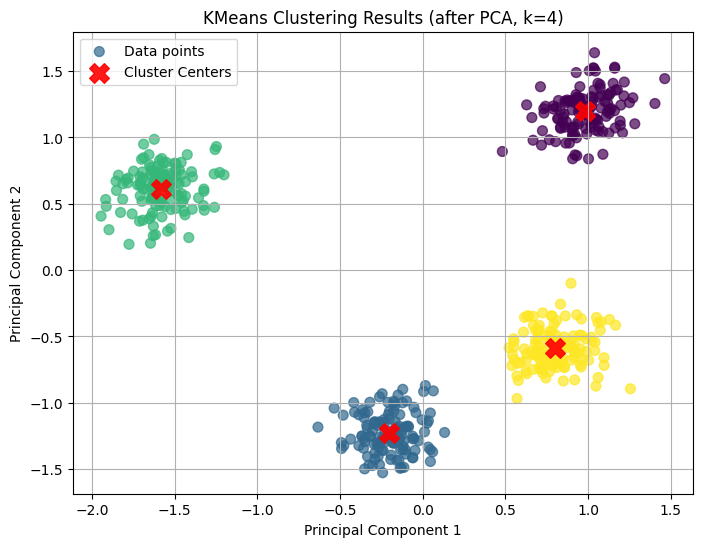

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Re-run the best algorithm (KMeans) with the best_k on X_p to get labels and centers for plotting
best_kmeans_model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels_pipeline = best_kmeans_model.fit_predict(X_p)
centers_pipeline = best_kmeans_model.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(X_p[:, 0], X_p[:, 1], c=labels_pipeline, cmap='viridis', s=50, alpha=0.7, label='Data points')
plt.scatter(centers_pipeline[:, 0], centers_pipeline[:, 1], c='red', s=200, alpha=0.9, marker='X', label='Cluster Centers')
plt.title(f'{best_algo} Clustering Results (after PCA, k={best_k})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()